# FIN 4600 Lab: How a Smart Contract Really Works

**Fintech Foundations · Michigan Technological University · goes with study guide gen-08 (Ethereum)**

In this lab you will run real Ethereum smart contracts on a **private blockchain that lives inside this notebook**. All the code is written for you. Your job is to **run it, read it, predict what will happen, try small experiments, and explain what you saw.** You do not need to know how to program.

**The main lesson is how cryptocurrency and smart contracts work.** Along the way, the comments in the code (the lines starting with `#`) explain what each line of Python does, so you will also pick up how Python and Jupyter notebooks work.

| Mission | What you will see | Points |
|---|---|---|
| 1 | Accounts, addresses, and why ether is counted in wei | 3 |
| 2 | Your first contract: a free *read* vs. a paid *transaction*, and what gas costs | 6 |
| 3 | Access control: one line of code decides who is allowed to act | 3 |
| 4 | The escrow from Nofsinger Figure 5.3, with no bank in the middle | 6 |
| 5 | A token the issuer can freeze, like USDT and USDC | 3 |
| 6 | The 2016 DAO hack, re-created, and the two-line fix | 6 |
| 7 | What it all cost, and what a Layer 2 changes | 3 |
| | **Total** | **30** |

**Nothing here touches a real network.** There is no wallet, no seed phrase and no money. The blockchain disappears when you close the notebook.

### Symbols used in this notebook

* 🔮 **Predict:** write down what you expect *before* you run the next cell.
* 🧪 **Experiment:** change one value in the code where it says so, run the cell again, and record what happened.
* ✍️ **Answer:** a written question that is graded. Double-click the cell to type in it, then press Shift+Enter.
* ✅ / ⛔ / ❌ in the output: something worked / the contract refused a request / a check did not pass.

## How to use a Jupyter notebook (read this first)

* A notebook is a list of **cells**. This cell is a *text* (Markdown) cell. Cells with a grey background and `[ ]:` on the left are *code* cells.
* Click a code cell and press **Shift+Enter** to run it. The output appears underneath and the cursor moves to the next cell.
* While a cell runs, the left side shows `[*]`. When it finishes, it shows a number such as `[4]`: the order in which cells were run.
* Everything you create (variables, the blockchain itself) lives in the notebook's memory, called the **kernel**. Run cells **from top to bottom**, because later cells use things made by earlier ones.
* If something gets confusing: menu **Kernel → Restart Kernel and Run All Cells**. That wipes memory and runs everything again in order.
* If a code cell's last line is just a name (like `costs`), Jupyter displays it as a table or value.

### Warm-up: Python in one cell

Run the cell below and compare each line with its output. Every idea here is used later in the lab.

In [1]:
# A line that starts with # is a COMMENT. Python ignores it; it is a note for people.

# A VARIABLE is a name that holds a value. "=" means "store the value on the right under the name on the left".
course = "FIN 4600"            # text goes in quotes and is called a "string"
price_of_ether = 2_330         # a number; the underscore is just a readable thousands separator

# print(...) is a FUNCTION: a named command. The things in the parentheses are its inputs ("arguments").
print(course)

# An f-string (note the f before the quote) fills in variables inside {curly braces}.
print(f"One ether costs about ${price_of_ether} in this lab.")

# A LIST holds several values in order, inside square brackets.
names = ["Alice", "Bob", "Carol"]
print(names[0])                # positions start at 0, so names[0] is the first item: Alice

# A DICTIONARY looks values up by a key, like a phone book: {key: value}.
balances = {"Alice": 10, "Bob": 3}
print(balances["Bob"])         # look up Bob's value: 3

# A FOR LOOP repeats the indented lines once for each item in the list.
for person in names:
    print("Hello,", person)

FIN 4600
One ether costs about $2330 in this lab.
Alice
3
Hello, Alice
Hello, Bob
Hello, Carol


## Mission 0: Start the blockchain

The next cell loads the lab's tools and starts a fresh private Ethereum blockchain. The first time you run it, it downloads the Solidity **compiler** (about 10 MB). A compiler translates human-readable contract code into the bytecode that the Ethereum Virtual Machine (EVM) runs.

The tools come from `helpers/chain.py` in this folder. You never have to open that file, but it is commented too if you are curious.

In [2]:
# "from X import a, b, c" loads specific tools (functions) from the file helpers/chain.py.
# The parentheses just let the list run over several lines.
from helpers.chain import (
    setup_compiler,   # downloads and selects the Solidity compiler
    read_contract,    # reads a contract's source code from the contracts/ folder
    compile_source,   # translates Solidity source code into EVM bytecode
    new_chain,        # starts a brand-new private blockchain in memory
    deploy,           # puts a compiled contract onto the blockchain
    transact,         # sends a transaction (it costs gas and can change data)
    try_transact,     # same, but if the contract says "no", prints why instead of stopping
    balance_eth,      # looks up how much ether an account or contract holds
    time_travel,      # moves the test blockchain's clock forward
    events,           # lists the log messages ("events") a contract has written
    gas_table,        # a table of every transaction we sent and the gas each one used
    check,            # prints ✅ if a statement is true, ❌ if not
)

# pandas is Python's most popular table library. "as pd" gives it a short nickname.
import pandas as pd

# Call the setup function. Its result is a short message, which print() displays.
print(setup_compiler())

# Start the blockchain. The result is an object (a bundle of data plus tools) that we store
# in a variable called w3, short for "Web3", the name of the Python library that talks to Ethereum.
w3 = new_chain()

# Objects have their own functions, called METHODS, reached with a dot: w3.is_connected()
print("Connected to our private test blockchain:", w3.is_connected())

solc 0.8.28 ready
Connected to our private test blockchain: True


## Mission 1: Accounts and ether (3 points)

On Ethereum an **account** is identified by an **address**: a 20-byte number written in hexadecimal (digits 0–9 and letters a–f), starting with `0x`. Whoever holds the account's **private key** can sign transactions for it. Our test blockchain creates 10 accounts and gives each one ether to play with.

Ether is divisible into tiny units called **wei**: 1 ether = 1,000,000,000,000,000,000 wei (10¹⁸). Gas prices are quoted in **gwei** (a billion wei).

In [3]:
# w3.eth.accounts is a LIST of the 10 test account addresses.
accounts = w3.eth.accounts

# "Unpacking": the first four addresses go into four variables at once, in order.
# accounts[:4] means "items 0, 1, 2 and 3 of the list".
alice, bob, carol, dave = accounts[:4]

# accounts[9] is the tenth (last) account. Mallory will be our attacker in Mission 6.
mallory = accounts[9]

# A dictionary that turns an address into a friendly name, so outputs are easier to read.
names = {alice: "Alice", bob: "Bob", carol: "Carol", dave: "Dave", mallory: "Mallory"}

# Build a table: one row per account. The part in [ ... for a in accounts ] is a "list comprehension":
# it runs the dictionary {...} once for every address a in the list, collecting the rows.
# names.get(a, "-") looks up a's name and uses "-" if it has none.
table = pd.DataFrame([
    {"name": names.get(a, "-"), "address": a, "balance_eth": balance_eth(w3, a)}
    for a in accounts
])

table   # a bare name on the last line: Jupyter displays it as a table

,name,address,balance_eth
0,Alice,0x7E5F4552091A69125d5DfCb7b8C2659029395Bdf,1000000.0
1,Bob,0x2B5AD5c4795c026514f8317c7a215E218DcCD6cF,1000000.0
2,Carol,0x6813Eb9362372EEF6200f3b1dbC3f819671cBA69,1000000.0
3,Dave,0x1efF47bc3a10a45D4B230B5d10E37751FE6AA718,1000000.0
4,-,0xe1AB8145F7E55DC933d51a18c793F901A3A0b276,1000000.0
5,-,0xE57bFE9F44b819898F47BF37E5AF72a0783e1141,1000000.0
6,-,0xd41c057fd1c78805AAC12B0A94a405c0461A6FBb,1000000.0
7,-,0xF1F6619B38A98d6De0800F1DefC0a6399eB6d30C,1000000.0
8,-,0xF7Edc8FA1eCc32967F827C9043FcAe6ba73afA5c,1000000.0
9,Mallory,0x4CCeBa2d7D2B4fdcE4304d3e09a1fea9fbEb1528,1000000.0


In [4]:
# How big is one ether in wei? w3.to_wei converts a number of ether into wei.
one_ether_in_wei = w3.to_wei(1, "ether")
print(f"1 ether = {one_ether_in_wei:,} wei")          # the ",": print with thousands separators

# And the other way: w3.from_wei converts wei back into ether (or gwei).
print("2 gwei =", w3.from_wei(w3.to_wei(2, "gwei"), "ether"), "ether")

# Balances are stored on the chain in wei. Here is Alice's raw balance, exactly as Ethereum keeps it.
raw = w3.eth.get_balance(alice)
print(f"Alice's balance in wei:   {raw:,}")
print(f"Alice's balance in ether: {balance_eth(w3, alice):,}")

1 ether = 1,000,000,000,000,000,000 wei
2 gwei = 2E-9 ether
Alice's balance in wei:   1,000,000,000,000,000,000,000,000
Alice's balance in ether: 1,000,000.0


✍️ **1a (3 pts).** An Ethereum address is public, like an account number, but only the holder of the matching private key can move its ether. Why is it safe to share your address but never your private key?

*Your answer:Your address lets others send you ether, but it can’t authorize transactions. Your private key proves ownership and allows spending, so anyone who gets it can move your ether

## Mission 2: Your first contract (6 points)

Here is `SimpleStorage`, the first example from the lecture. It stores one number, `storedRate`. Solidity uses `//` for comments, where Python uses `#`.

In [5]:
# read_contract reads the text of a file in the contracts/ folder and returns it as a string.
storage_src = read_contract("SimpleStorage.sol")
print(storage_src)

// SPDX-License-Identifier: MIT
pragma solidity ^0.8.24;

contract SimpleStorage {
    uint256 public storedRate;  // anyone can read it

    event RateChanged(address by, uint256 newRate);

    function setRate(uint256 newRate) external {
        storedRate = newRate;   // a write: costs gas
        emit RateChanged(msg.sender, newRate);
    }
}



**Compiling** turns the source into **bytecode** (what the EVM runs) and an **ABI** (Application Binary Interface): a menu of functions that outside programs, like this notebook, are allowed to call.

**Deploying** is itself a transaction: it stores the bytecode on the blockchain at a new address. From then on, every node holds a copy and anyone can call it.

In [6]:
# Compile. The result is a dictionary holding the ABI and the bytecode.
storage_compiled = compile_source(storage_src, "SimpleStorage")

# Pull the function names out of the ABI (only the entries whose "type" is "function").
menu = [item["name"] for item in storage_compiled["abi"] if item["type"] == "function"]
print("Functions on the menu (the ABI):", menu)

# Bytecode is stored as hexadecimal text: 2 characters per byte, so divide the length by 2.
# "//" in Python means whole-number division.
print("Bytecode size:", len(storage_compiled["bytecode"]) // 2, "bytes")
print("First bytes of the bytecode:", storage_compiled["bytecode"][:40], "...")

# Deploy the contract, sending the transaction from Alice's account.
# sender=alice is a KEYWORD ARGUMENT: the input is named so its meaning is clear.
storage = deploy(w3, storage_compiled, sender=alice)

Functions on the menu (the ABI): ['setRate', 'storedRate']
Bytecode size: 507 bytes
First bytes of the bytecode: 6080604052348015600e575f5ffd5b506101df80 ...
✅ deploy SimpleStorage: address 0xF2E246BB..., gas used 156,795


### A free *call* vs. a paid *transaction*

* A **call** only *reads*. Any node can answer it from its own copy of the chain, so it is free and changes nothing.
* A **transaction** *writes*. It must be signed, put into a block, and run by every node, so it costs **gas**.

🔮 **Predict:** the next cell reads the rate, changes it, and reads it again. Which of those three steps will show a gas cost? 



In [7]:
# 🧪 EXPERIMENT (Mission 2): change this number, then run this cell again.
NEW_RATE = 525

# storage.functions.storedRate() picks the storedRate function off the contract's menu;
# .call() asks for its value. A call is free and creates no transaction.
print("Rate before:", storage.functions.storedRate().call())

# transact(...) sends a real transaction from Alice that runs setRate(NEW_RATE) on every node.
# It returns a RECEIPT: the blockchain's record of what happened (block number, gas used, ...).
receipt = transact(w3, storage.functions.setRate(NEW_RATE), sender=alice)

print("Rate after: ", storage.functions.storedRate().call())
print("Recorded in block number:", receipt.blockNumber)

# The contract also wrote an EVENT (a log message). Show all RateChanged events as a table.
events(storage, "RateChanged")

Rate before: 0
✅ setRate: gas used 45,301
Rate after:  525
Recorded in block number: 2


,by,newRate,block
0,0x7E5F4552091A69125d5DfCb7b8C2659029395Bdf,525,2


### What did that cost?

On the real Ethereum network you pay **gas used × gas price**. We use an illustrative gas price of **2 gwei** and an ether price of **$2,330** (November 4, 2026).

In [8]:
# Constants are often written in CAPITALS by convention. We reuse these in Mission 7.
GAS_PRICE_GWEI = 2        # price of one unit of gas, in gwei
ETH_USD = 2330            # dollars per ether

gas_used = receipt.gasUsed                       # how much gas setRate used (read from the receipt)
fee_eth = gas_used * GAS_PRICE_GWEI * 1e-9       # 1e-9 is scientific notation for 0.000000001 (1 gwei in ether)
fee_usd = fee_eth * ETH_USD                      # convert ether to dollars

# Inside {...}, the part after ":" formats the number: ",": thousands separator; ".10f": 10 decimals.
print(f"Gas used: {gas_used:,}")
print(f"Fee: {gas_used:,} gas × {GAS_PRICE_GWEI} gwei = {fee_eth:.10f} ETH ≈ ${fee_usd:.3f}")

Gas used: 45,301
Fee: 45,301 gas × 2 gwei = 0.0000906020 ETH ≈ $0.211


🔮 **Predict:** Dave did not deploy this contract. If Dave tries to change the rate, will the contract let him?

In [9]:
# Dave (not the deployer) sends a transaction asking to set the rate to 9999.
transact(w3, storage.functions.setRate(9999), sender=dave)

# Read the rate back. Did Dave's change stick?
print("Rate now:", storage.functions.storedRate().call())

# check(statement, message if true, message if false) prints ✅ or ❌.
check(storage.functions.storedRate().call() == 9999,
      "Dave was able to change the rate", "Dave could not change the rate")

✅ setRate: gas used 28,201
Rate now: 9999
✅ Dave was able to change the rate


True

✍️ **2a (3 pts).** Your 🔮 prediction about which step costs gas: were you right? In your own words, why is reading free but writing paid?

*Your answer: Yes. Reading only retrieves existing data, while writing changes blockchain state and requires validators to process and record the transaction, which costs gas.

✍️ **2b (3 pts).** Dave is a stranger, yet he changed the rate. Why? If this number were the interest rate on a loan contract, what could go wrong?

*Your answer: Dave could change it because the contract has no access control. In a loan contract, anyone might alter the interest rate, causing unfair or incorrect payments.



## Mission 3: One line decides who may act (3 points)

`OwnedStorage` fixes Dave's trick with two additions:

* a **constructor**, which runs once when the contract is deployed and records the deployer as `owner`, and
* a **`require`** line: if its condition is false, the contract refuses ("reverts") and **nothing changes**.

In Solidity, `msg.sender` always means "the account that sent this transaction". Nobody can fake it, because every transaction is signed with the sender's private key.

In [10]:
# A Python string in triple quotes """ ... """ can span many lines. We keep the Solidity code in one,
# so you can edit it right here for the experiment below.
owned_src = """
// SPDX-License-Identifier: MIT
pragma solidity ^0.8.24;

contract OwnedStorage {
    uint256 public storedRate;
    address public owner;

    constructor() {
        owner = msg.sender;            // whoever deploys the contract becomes the owner
    }

    function setRate(uint256 newRate) external {
        require(msg.sender == owner, "only owner");   // the one line that decides who may act
        storedRate = newRate;
    }
}
"""

# Compile and deploy in one line: compile_source(...) runs first, and its result goes straight into deploy(...).
owned = deploy(w3, compile_source(owned_src, "OwnedStorage"), sender=alice)
print("Owner recorded by the constructor:", names[owned.functions.owner().call()])

✅ deploy OwnedStorage: address 0xDe09E74d..., gas used 237,841
Owner recorded by the constructor: Alice


🔮 **Predict:** Alice tries to set the rate to 450, then Dave tries to set it to 1. What happens to each?

In [11]:
# try_transact returns TWO values (a "tuple"): whether it worked (True/False), and the receipt or the refusal reason.
# We unpack them into two variables each.
ok_alice, _ = try_transact(w3, owned.functions.setRate(450), sender=alice, label="Alice sets 450")   # "_" = a value we ignore
ok_dave, reason = try_transact(w3, owned.functions.setRate(1), sender=dave, label="Dave tries 1")

print("Rate now:", owned.functions.storedRate().call())
check(ok_alice, "the owner can set the rate", "the owner could not set the rate")
check(not ok_dave, "the stranger was refused: " + str(reason), "the stranger was NOT refused")

✅ Alice sets 450: gas used 45,877
⛔ Dave tries 1: refused (reverted), reason: 'only owner' (nothing changed on chain)
Rate now: 450
✅ the owner can set the rate
✅ the stranger was refused: only owner


True

🧪 **Experiment:** in the code cell that defines `owned_src` (two cells up), put `//` at the very start of the `require(...)` line so Solidity treats it as a comment. Run that cell, then run the Alice-and-Dave cell again. **Record what happens.** Then remove the `//` and run both cells again to restore the protection.

✍️ **3a (3 pts).** What happened in the 🧪 experiment when the `require` line was commented out? What does that tell you about how much of a contract's security can rest on a single line of code?

*Your answer: With require commented out, the unauthorized transaction succeeded. It shows that one missing check can undermine a contract’s security.

## Mission 4: The escrow from Figure 5.3 (6 points)

Alice is buying a used bike from Bob for **2 ether**. Instead of a bank in the middle, Alice deploys an escrow contract and deposits the money into it. Only Alice can release the money to Bob. If Bob never delivers, Alice can take a refund after the deadline. Read the contract: every `require` is one of the deal's conditions.

In [12]:
escrow_src = read_contract("Escrow.sol")
print(escrow_src)
escrow_compiled = compile_source(escrow_src, "Escrow")

// SPDX-License-Identifier: MIT
pragma solidity ^0.8.24;

contract Escrow {
    address public buyer;
    address payable public seller;
    uint256 public deadline;
    bool public settled;

    constructor(address payable _seller, uint256 daysToDeliver) payable {
        require(msg.value > 0, "deposit required");
        buyer = msg.sender;
        seller = _seller;
        deadline = block.timestamp + daysToDeliver * 1 days;
    }

    function confirmDelivery() external {
        require(msg.sender == buyer, "only buyer");
        require(!settled, "already settled");
        settled = true;                    // effects before interaction
        (bool ok, ) = seller.call{value: address(this).balance}("");
        require(ok, "payment failed");
    }

    function refund() external {
        require(msg.sender == buyer, "only buyer");
        require(!settled, "already settled");
        require(block.timestamp > deadline, "too early");
        settled = true;
        (bool ok, )

In [13]:
# Remember Bob's balance now, so we can see what he gains later.
bob_start = balance_eth(w3, bob)

# Deploy the escrow. The extra inputs bob and 7 go to the contract's constructor: (seller, daysToDeliver).
# value_eth=2 sends 2 ether along with the deployment: that is Alice's deposit.
escrow = deploy(w3, escrow_compiled, bob, 7, sender=alice, value_eth=2,
                label="deploy Escrow (Alice deposits 2 ETH)")

print("The escrow contract now holds:", balance_eth(w3, escrow.address), "ETH")
print("Buyer: ", names[escrow.functions.buyer().call()])
print("Seller:", names[escrow.functions.seller().call()])

✅ deploy Escrow (Alice deposits 2 ETH): address 0xB9816fC5..., gas used 605,475
The escrow contract now holds: 2.0 ETH
Buyer:  Alice
Seller: Bob


🔮 **Predict:** before running the next cell, write *succeeds* or *refused* (and why) for each of these four attempts, in order:

1. Bob tries to release the money to himself.
2. Alice asks for a refund on day 0.
3. Alice confirms delivery.
4. Alice confirms delivery a second time.

*Your predictions:* 1. ___ 2. ___ 3. ___ 4. ___

In [14]:
# Four attempts, in order. try_transact prints ✅ if the contract accepted, ⛔ and the reason if it refused.
try_transact(w3, escrow.functions.confirmDelivery(), sender=bob,   label="1. Bob tries to pay himself")
try_transact(w3, escrow.functions.refund(),          sender=alice, label="2. Alice asks for a refund on day 0")
try_transact(w3, escrow.functions.confirmDelivery(), sender=alice, label="3. Alice confirms delivery")
try_transact(w3, escrow.functions.confirmDelivery(), sender=alice, label="4. Alice confirms again")

# round(x, 6) rounds to 6 decimal places.
print("Bob gained:", round(balance_eth(w3, bob) - bob_start, 6), "ETH")
print("Escrow now holds:", balance_eth(w3, escrow.address), "ETH")

⛔ 1. Bob tries to pay himself: refused (reverted), reason: 'only buyer' (nothing changed on chain)
⛔ 2. Alice asks for a refund on day 0: refused (reverted), reason: 'too early' (nothing changed on chain)
✅ 3. Alice confirms delivery: gas used 57,481
⛔ 4. Alice confirms again: refused (reverted), reason: 'already settled' (nothing changed on chain)
Bob gained: 2.0 ETH
Escrow now holds: 0.0 ETH


Now the unhappy path: Carol buys a bike from Dave for 1 ether, and Dave never delivers. Our test blockchain lets us move its clock forward, something you obviously cannot do on the real network.

In [15]:
# 🧪 EXPERIMENT (Mission 4): change DAYS_LATER to 5 and run this cell again. What changes?
DAYS_LATER = 8

# A second escrow: Carol is the buyer, Dave the seller, 1 ether deposit, 7 days to deliver.
escrow2 = deploy(w3, escrow_compiled, dave, 7, sender=carol, value_eth=1,
                 label="deploy Escrow (Carol deposits 1 ETH)")

# Move the blockchain's clock forward, then Carol asks for her money back.
time_travel(w3, DAYS_LATER)
try_transact(w3, escrow2.functions.refund(), sender=carol, label=f"Carol asks for a refund on day {DAYS_LATER}")

print("Escrow 2 now holds:", balance_eth(w3, escrow2.address), "ETH")

✅ deploy Escrow (Carol deposits 1 ETH): address 0x82c839Fa..., gas used 605,475
⏩ clock moved forward 8 days
✅ Carol asks for a refund on day 8: gas used 55,080
Escrow 2 now holds: 0.0 ETH


✍️ **4a (3 pts).** Compare your four 🔮 predictions with what happened. For each one you got wrong (if any), which `require` line in the contract explains the result?

*Your answer: Any prediction I got wrong was explained by a require check: it restricts who can act and when the escrow funds can be released.

✍️ **4b (3 pts).** The escrow replaced the banks in Figure 5.3. Name one job the banks did that this contract cannot do, and who or what would have to do it instead.

*Your answer: The contract can’t inspect the real-world item or resolve disputes. A trusted person or institution would need to verify delivery and decide whether the funds should be released.

## Mission 5: A token the issuer can freeze (3 points)

Alice issues 1,000,000 **Husky Dollars**. A token is not a coin that moves around: it is a **ledger inside a contract**, a `mapping` (Solidity's version of a dictionary) from each address to its balance. A "transfer" just subtracts from one entry and adds to another. Notice the `freeze` function at the bottom.

In [16]:
token_src = read_contract("ClassToken.sol")
print(token_src)

# Deploy with 1,000,000 Husky Dollars, all credited to Alice (the issuer) by the constructor.
token = deploy(w3, compile_source(token_src, "ClassToken"), 1_000_000, sender=alice)

# Alice pays Carol 500 Husky Dollars.
transact(w3, token.functions.transfer(carol, 500), sender=alice, label="Alice pays Carol 500")

// SPDX-License-Identifier: MIT
pragma solidity ^0.8.24;

contract ClassToken {
    string public name = "Husky Dollar";
    address public issuer;
    mapping(address => uint256) public balanceOf;
    mapping(address => bool) public frozen;

    constructor(uint256 supply) {
        issuer = msg.sender;
        balanceOf[msg.sender] = supply;
    }

    function transfer(address to, uint256 amount) external {
        require(!frozen[msg.sender], "account frozen");
        require(balanceOf[msg.sender] >= amount, "insufficient balance");
        balanceOf[msg.sender] -= amount;
        balanceOf[to] += amount;
    }

    function freeze(address account) external {
        require(msg.sender == issuer, "only issuer");
        frozen[account] = true;
    }
}

✅ deploy ClassToken: address 0x5CF7F966..., gas used 640,468
✅ Alice pays Carol 500: gas used 52,409


AttributeDict({'blockHash': HexBytes('0x72c6af12f8b90b7e4b33ced1dddcc7afeaa6cd6c4fce7022a70f494ccb374c79'),
 'blockNumber': 13,
 'contractAddress': None,
 'cumulativeGasUsed': 52409,
 'effectiveGasPrice': 1000000000,
 'from': '0x7E5F4552091A69125d5DfCb7b8C2659029395Bdf',
 'gasUsed': 52409,
 'logs': [],
 'state_root': b'\x01',
 'status': 1,
 'to': '0x5CF7F96627F3C9903763d128A1cc5D97556A6b99',
 'transactionHash': HexBytes('0x21a5cb14153c61d5a29aa6bc5d6c5ac3bcad08ea494f3c09575b0f2d2a5ab571'),
 'transactionIndex': 0,
 'type': 2})

In [17]:
# A small FUNCTION we define ourselves with "def". It prints everyone's token balance.
# The indented lines are the function's body; they run each time we call show_balances().
def show_balances():
    for person in (alice, carol, dave):            # loop over three addresses
        amount = token.functions.balanceOf(person).call()
        frozen = token.functions.frozen(person).call()
        print(f"{names[person]:6} {amount:>9,} Husky Dollars   frozen: {frozen}")

show_balances()

Alice    999,500 Husky Dollars   frozen: False
Carol        500 Husky Dollars   frozen: False
Dave           0 Husky Dollars   frozen: False


🔮 **Predict:** Alice freezes Carol's account. Then Carol tries to pay Dave 100, and Dave tries to freeze Alice. What happens to each?

In [18]:
transact(w3, token.functions.freeze(carol), sender=alice, label="Alice (issuer) freezes Carol")
try_transact(w3, token.functions.transfer(dave, 100), sender=carol, label="Carol tries to pay Dave 100")
try_transact(w3, token.functions.freeze(alice), sender=dave, label="Dave tries to freeze Alice")

show_balances()

✅ Alice (issuer) freezes Carol: gas used 46,336
⛔ Carol tries to pay Dave 100: refused (reverted), reason: 'account frozen' (nothing changed on chain)
⛔ Dave tries to freeze Alice: refused (reverted), reason: 'only issuer' (nothing changed on chain)
Alice    999,500 Husky Dollars   frozen: False
Carol        500 Husky Dollars   frozen: True
Dave           0 Husky Dollars   frozen: False


✍️ **5a (3 pts).** Tether (USDT) and Circle (USDC) have freeze (blacklist) functions like this one, and used them after the October 2026 Binance theft (ce-02). Give one argument that this power is good for users and one that it is a risk.

*Your answer: Freezing stolen funds may help prevent thieves from moving them. Risk: The issuer could freeze legitimate users’ funds by mistake or misuse that power.

## Mission 6: Re-create the DAO hack, then fix it (6 points)

In June 2016 an attacker drained about 3.6 million ether from The DAO. The bug was in the **order of two steps** in a withdraw function. `VulnerableBank` has the same bug: its `withdraw()` **sends the money first** and **updates its books second**.

The `Attacker` contract exploits this. When a contract receives ether, a special function called `receive()` runs automatically. The attacker's `receive()` calls `withdraw()` **again**, before the bank has set the attacker's balance to zero, so the bank still thinks the attacker is owed money.

In [19]:
bank_src = read_contract("VulnerableBank.sol")
print(bank_src)
print(read_contract("Attacker.sol"))
attacker_compiled = compile_source(read_contract("Attacker.sol"), "Attacker")

// SPDX-License-Identifier: MIT
pragma solidity ^0.8.24;

// A tiny bank with the same bug that drained The DAO in 2016.
contract VulnerableBank {
    mapping(address => uint256) public balanceOf;

    function deposit() external payable {
        balanceOf[msg.sender] += msg.value;
    }

    function withdraw() external {
        uint256 amount = balanceOf[msg.sender];
        require(amount > 0, "nothing to withdraw");
        (bool ok, ) = msg.sender.call{value: amount}("");  // 1. send the money...
        require(ok, "send failed");
        balanceOf[msg.sender] = 0;                         // 2. ...then update the books (too late!)
    }
}

// SPDX-License-Identifier: MIT
pragma solidity ^0.8.24;

interface IBank {
    function deposit() external payable;
    function withdraw() external;
}

// Deposits 1 ether, then keeps calling withdraw() from inside its own receive() function.
contract Attacker {
    IBank public bank;
    address public owner;
    uint256 public reentries;


🔮 **Predict:** three honest savers each deposit 3 ETH (the bank holds 9). Mallory deposits **1 ETH** and attacks. How much will she walk away with?

In [20]:
# 🧪 EXPERIMENT (Mission 6): change SAVER_DEPOSIT to 5 and run this cell again.
SAVER_DEPOSIT = 3

# Start a FRESH blockchain for a clean experiment (everything from Missions 1-5 is wiped).
w3 = new_chain()
alice, bob, carol, dave = w3.eth.accounts[:4]
mallory = w3.eth.accounts[9]

# Alice opens the bank; Bob, Carol and Dave each deposit.
bank = deploy(w3, compile_source(bank_src, "VulnerableBank"), sender=alice)
for saver in (bob, carol, dave):
    transact(w3, bank.functions.deposit(), sender=saver, value_eth=SAVER_DEPOSIT,
             label=f"deposit {SAVER_DEPOSIT} ETH")
print("Bank holds:", balance_eth(w3, bank.address), "ETH of honest savers' money\n")   # "\n" = blank line

# Mallory deploys her attack contract, pointing it at the bank, and attacks with 1 ether.
attacker = deploy(w3, attacker_compiled, bank.address, sender=mallory)
transact(w3, attacker.functions.attack(), sender=mallory, value_eth=1, label="Mallory attacks with 1 ETH")

print("\nBank holds now:  ", balance_eth(w3, bank.address), "ETH")
print("Attacker holds:  ", balance_eth(w3, attacker.address), "ETH")
print("Times re-entered:", attacker.functions.reentries().call())

✅ deploy VulnerableBank: address 0xF2E246BB..., gas used 320,681
✅ deposit 3 ETH: gas used 43,601
✅ deposit 3 ETH: gas used 43,601
✅ deposit 3 ETH: gas used 43,601
Bank holds: 9.0 ETH of honest savers' money

✅ deploy Attacker: address 0x48c078E4..., gas used 530,321
✅ Mallory attacks with 1 ETH: gas used 148,893

Bank holds now:   0.0 ETH
Attacker holds:   10.0 ETH
Times re-entered: 9


### The fix: change the order

Below is `SafeBank`. It is identical except that `withdraw()` sets the balance to zero **before** sending the money. This rule is called **checks, effects, interactions**: check the conditions, update your own records, and only then send money to anyone else. (The escrow in Mission 4 does the same thing: `settled = true;` comes before the payment.)

🔮 **Predict:** Mallory runs exactly the same attack against `SafeBank`. What happens?

In [21]:
safe_src = """
// SPDX-License-Identifier: MIT
pragma solidity ^0.8.24;

contract SafeBank {
    mapping(address => uint256) public balanceOf;

    function deposit() external payable {
        balanceOf[msg.sender] += msg.value;
    }

    function withdraw() external {
        uint256 amount = balanceOf[msg.sender];
        require(amount > 0, "nothing to withdraw");
        balanceOf[msg.sender] = 0;                         // EFFECT first: update the books
        (bool ok, ) = msg.sender.call{value: amount}("");  // INTERACTION last: send the money
        require(ok, "send failed");
    }
}
"""

w3 = new_chain()
alice, bob, carol, dave = w3.eth.accounts[:4]
mallory = w3.eth.accounts[9]

safe = deploy(w3, compile_source(safe_src, "SafeBank"), sender=alice)
for saver in (bob, carol, dave):
    transact(w3, safe.functions.deposit(), sender=saver, value_eth=3, label="deposit 3 ETH")

attacker = deploy(w3, attacker_compiled, safe.address, sender=mallory)
attacked, reason = try_transact(w3, attacker.functions.attack(), sender=mallory, value_eth=1,
                                label="Mallory attacks with 1 ETH")

# An honest saver can still withdraw normally.
try_transact(w3, safe.functions.withdraw(), sender=bob, label="Bob withdraws his 3 ETH")

check(not attacked, "the attack was refused", "the attack worked")
check(balance_eth(w3, safe.address) == 6, "Carol's and Dave's 6 ETH is safe", "the bank lost money")

✅ deploy SafeBank: address 0xF2E246BB..., gas used 320,681
✅ deposit 3 ETH: gas used 43,601
✅ deposit 3 ETH: gas used 43,601
✅ deposit 3 ETH: gas used 43,601
✅ deploy Attacker: address 0x48c078E4..., gas used 530,321
⛔ Mallory attacks with 1 ETH: refused (reverted), reason: 'send failed' (nothing changed on chain)
✅ Bob withdraws his 3 ETH: gas used 28,707
✅ the attack was refused
✅ Carol's and Dave's 6 ETH is safe


True

✍️ **6a (3 pts).** Mallory deposited 1 ether. How much did she take out, and how many times did her contract re-enter `withdraw()`? Explain in your own words why the bank kept paying.

*Your answer: Mallory took 10 ETH and re-entered withdraw() 9 times. The bank sent the ether before updating her recorded balance, so each re-entry still saw her as owed 1 ETH.

✍️ **6b (3 pts).** Why did the same attack fail against `SafeBank`? Trace what happens when the attacker's `receive()` calls `withdraw()` the second time.

*Your answer: SafeBank zeroes her balance before payment, so the re-entry fails the balance check.



## Mission 7: What did it all cost? (3 points)

Every transaction since the last `new_chain()` (the `SafeBank` experiment) was logged. Let's turn gas into money.

In [22]:
# 🧪 EXPERIMENT (Mission 7): mainnet gas prices jump on busy days. Change GAS_PRICE_GWEI to 50 and re-run.
GAS_PRICE_GWEI = 2
ETH_USD = 2330

costs = gas_table()                                              # a pandas DataFrame (a table)
costs["fee_eth"] = costs["gas_used"] * GAS_PRICE_GWEI * 1e-9     # new column: the formula runs on every row at once
costs["fee_usd"] = (costs["fee_eth"] * ETH_USD).round(3)         # new column in dollars, rounded to 3 decimals

costs   # display the table

,operation,gas_used,block,fee_eth,fee_usd
0,deploy SafeBank,320681,1,0.000641,1.494
1,deposit 3 ETH,43601,2,0.000087,0.203
2,deposit 3 ETH,43601,3,0.000087,0.203
3,deposit 3 ETH,43601,4,0.000087,0.203
4,deploy Attacker,530321,5,0.001061,2.471
5,Bob withdraws his 3 ETH,28707,6,0.000057,0.134


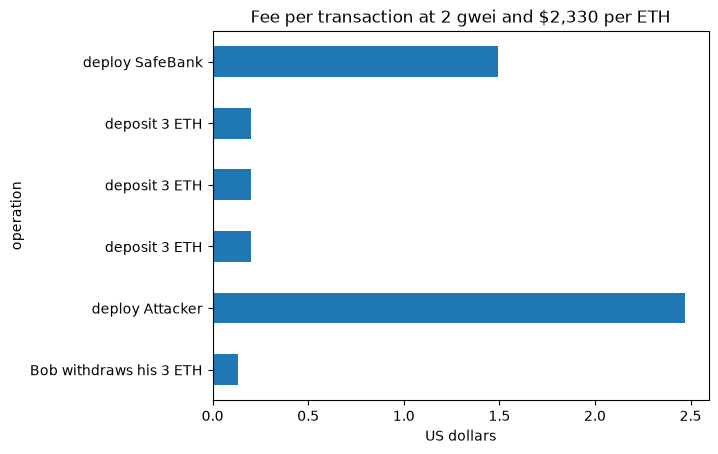

In [23]:
# Draw a horizontal bar chart straight from the table: one bar per operation, length = fee in dollars.
ax = costs.plot.barh(x="operation", y="fee_usd", legend=False,
                     title=f"Fee per transaction at {GAS_PRICE_GWEI} gwei and ${ETH_USD:,} per ETH")
ax.set_xlabel("US dollars")       # label the horizontal axis
ax.invert_yaxis()                 # list operations top to bottom in the order they happened

✍️ **7a (3 pts).** Using the lecture, explain how a Layer 2 rollup makes the same transaction cheaper, and what you give up.

*Your answer: A rollup bundles many transactions and posts a compressed summary to Ethereum, sharing the cost. You rely on the rollup’s systems and may face extra trust or withdrawal delays.

## Submit

1. Menu **Kernel → Restart Kernel and Run All Cells**. Every cell should run; your 🧪 experiment values can be back at their originals or left changed, as long as your written answers record what you saw.
2. Make sure every ✍️ answer is filled in, then save (Ctrl+S or ⌘+S).
3. Record your work with git from the terminal (practice for the command line):

```
git add smart_contracts_lab.ipynb
git commit -m "Complete smart contracts lab"
```

4. Submit the notebook as directed in Canvas.

**Never** paste a seed phrase or private key into a notebook or website, and never deploy classroom code to the real Ethereum network.